In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [71]:
from sklearn.datasets import make_classification

In [72]:
X, y = make_classification(n_samples= 1000, n_classes= 2, n_clusters_per_class= 1, n_features= 2, n_informative= 1, n_redundant= 0, n_repeated= 0, random_state= 42, class_sep= 3)

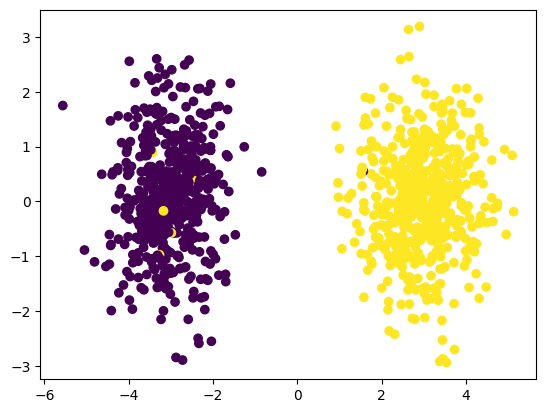

In [73]:
plt.scatter(X[:, 0], X[:, 1], c = y)

In [74]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state= 42)

In [79]:
class own_Perceptron:

    def __init__(self, lr, epochs):
        self.lr = lr
        self.epochs = epochs
        self.weights = None

    def step(self, x):
        return 1 if x >= 0 else 0
    
    def fit(self, X_train, y_train):
        X_train = np.insert(X_train, 0, 1, axis= 1)
        self.weights = np.ones(X_train.shape[1])
        for i in range(self.epochs):
            j = np.random.randint(0, X_train.shape[0])
            y_hat = self.step(np.dot(self.weights, X_train[j]))
            self.weights = self.weights + self.lr * (X_train[j]) * (y[j] - y_hat)
        return self.weights

    def predict(self, X_test):
        return self.step(np.dot(self.weights, X_test))

In [80]:
pr = own_Perceptron(0.01, 10000)

In [81]:
coeffs = pr.fit(X_train, y_train)
intercept_ = coeffs[0]
coeff_ = coeffs[1:]

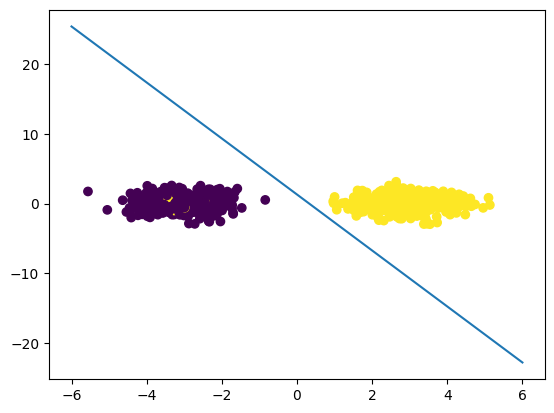

In [82]:
x_input = np.linspace(-6, 6, 200)
m = -(coeff_[0]/coeff_[1])
b = -(intercept_/coeff_[1])
y_input = m * x_input + b
plt.scatter(X_train[:, 0], X_train[:, 1], c = y_train)
plt.plot(x_input, y_input)
plt.show()